In [11]:
X_config = ["hum_carrasco","hum_salto","tmax_carrasco","tmin_carrasco","tmax_salto","tmin_salto",
     "dir_viento_carrasco_prom","int_viento_carrasco_prom",
     "int_racha_viento_carrasco_prom","dir_viento_salto_prom","int_viento_salto_prom",
     "int_racha_viento_salto_prom","vis_carrasco_prom","vis_salto_prom","fen_carrasco_17", "fase_lunar"]


y_config = ["dia_lluvioso", "mes_lluvioso"]

In [14]:
import algoritmos_clasificacion as t
import importlib
importlib.reload(t)

# Carga dataset
S = t.cargarDataset("data_dia1")

resultados_validacion_id3 = {}

for target in y_config:

    # Configuración atributos y objetivo válidos
    X = S[X_config]

    y = S[target].squeeze() #pasa de df a serie

    # #configuración de hiperparámetros a evaluar
    criterios = ["gain", "gini", "gain_ratio"]
    min_info_gains = [0.003, 0.004, 0.006, 0.008]

    # Train/Test split (80/20 estratificado)
    X_train, X_test, y_train, y_test, = t.split_data(X,y)

    # Validación cruzada para selección de hiperparámetros
    df_validacion_id3, best_cfg_F, best_cfg_A, best_cfg_P, best_cfg_R = t.validarModelo(X_train, y_train, n_splits=5, criterios=criterios, hiperparams=min_info_gains)

    resultados_validacion_id3[target] = df_validacion_id3

    print("\n Resultados CV para target:", target)
    print(df_validacion_id3.round(4).to_string(index=False))
#tiempo est: 28min

#Se puede reducir criterios y min_info_gain para hacerlo más veloz, configuracion hallada:
# Resultados CV
#   criterio  min_info_gain  accuracy_mean  accuracy_std  f1_mean  f1_std  recall_mean  recall_std  precision_mean  precision_std
#       gain          0.003         0.6988        0.0059   0.2806  0.0120       0.2652      0.0135          0.2981         0.0120
#       gain          0.004         0.6990        0.0059   0.2802  0.0128       0.2646      0.0150          0.2981         0.0120
#       gain          0.006         0.7022        0.0050   0.2708  0.0140       0.2499      0.0176          0.2960         0.0104
#       gain          0.008         0.7045        0.0072   0.2689  0.0128       0.2454      0.0154          0.2978         0.0130
#       gini          0.003         0.7031        0.0053   0.2801  0.0141       0.2610      0.0178          0.3027         0.0107
#       gini          0.004         0.7135        0.0061   0.2746  0.0097       0.2449      0.0118          0.3130         0.0109
#       gini          0.006         0.7305        0.0097   0.2456  0.0171       0.1987      0.0222          0.3247         0.0147
#       gini          0.008         0.7530        0.0032   0.2105  0.0247       0.1495      0.0232          0.3603         0.0103
# gain_ratio          0.003         0.6982        0.0080   0.2829  0.0139       0.2688      0.0148          0.2989         0.0156
# gain_ratio          0.004         0.6991        0.0078   0.2813  0.0162       0.2660      0.0188          0.2989         0.0159
# gain_ratio          0.006         0.7066        0.0100   0.2688  0.0101       0.2435      0.0136          0.3008         0.0149
# gain_ratio          0.008         0.7232        0.0097   0.2463  0.0175       0.2043      0.0167          0.3111         0.0237 


 Resultados CV para target: dia_lluvioso
  criterio  min_info_gain  accuracy_mean  accuracy_std  f1_mean  f1_std  recall_mean  recall_std  precision_mean  precision_std
      gain          0.003         0.6988        0.0059   0.2806  0.0120       0.2652      0.0135          0.2981         0.0120
      gain          0.004         0.6990        0.0059   0.2802  0.0128       0.2646      0.0150          0.2981         0.0120
      gain          0.006         0.7022        0.0050   0.2708  0.0140       0.2499      0.0176          0.2960         0.0104
      gain          0.008         0.7045        0.0072   0.2689  0.0128       0.2454      0.0154          0.2978         0.0130
      gini          0.003         0.7031        0.0053   0.2801  0.0141       0.2610      0.0178          0.3027         0.0107
      gini          0.004         0.7135        0.0061   0.2746  0.0097       0.2449      0.0118          0.3130         0.0109
      gini          0.006         0.7305        0.0097   0.245

C:\Users\cabre\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\cabre\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\cabre\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\metrics\_classification.py:17


 Resultados CV para target: mes_lluvioso
  criterio  min_info_gain  accuracy_mean  accuracy_std  f1_mean  f1_std  recall_mean  recall_std  precision_mean  precision_std
      gain          0.003         0.6155        0.0245   0.1376  0.1715       0.1213      0.1561          0.1648         0.2019
      gain          0.004         0.6345        0.0001   0.0000  0.0000       0.0000      0.0000          0.0000         0.0000
      gain          0.006         0.6345        0.0001   0.0000  0.0000       0.0000      0.0000          0.0000         0.0000
      gain          0.008         0.6345        0.0001   0.0000  0.0000       0.0000      0.0000          0.0000         0.0000
      gini          0.003         0.6345        0.0001   0.0000  0.0000       0.0000      0.0000          0.0000         0.0000
      gini          0.004         0.6345        0.0001   0.0000  0.0000       0.0000      0.0000          0.0000         0.0000
      gini          0.006         0.6345        0.0001   0.000

C:\Users\cabre\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


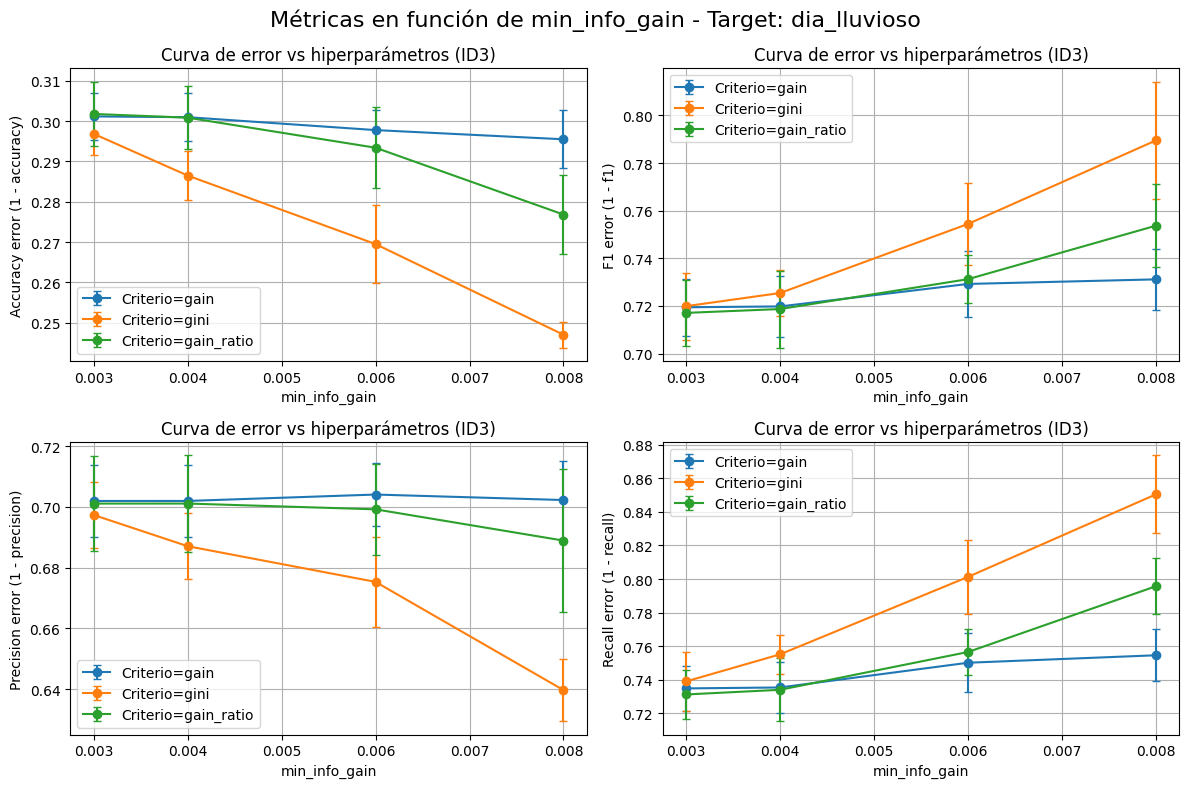

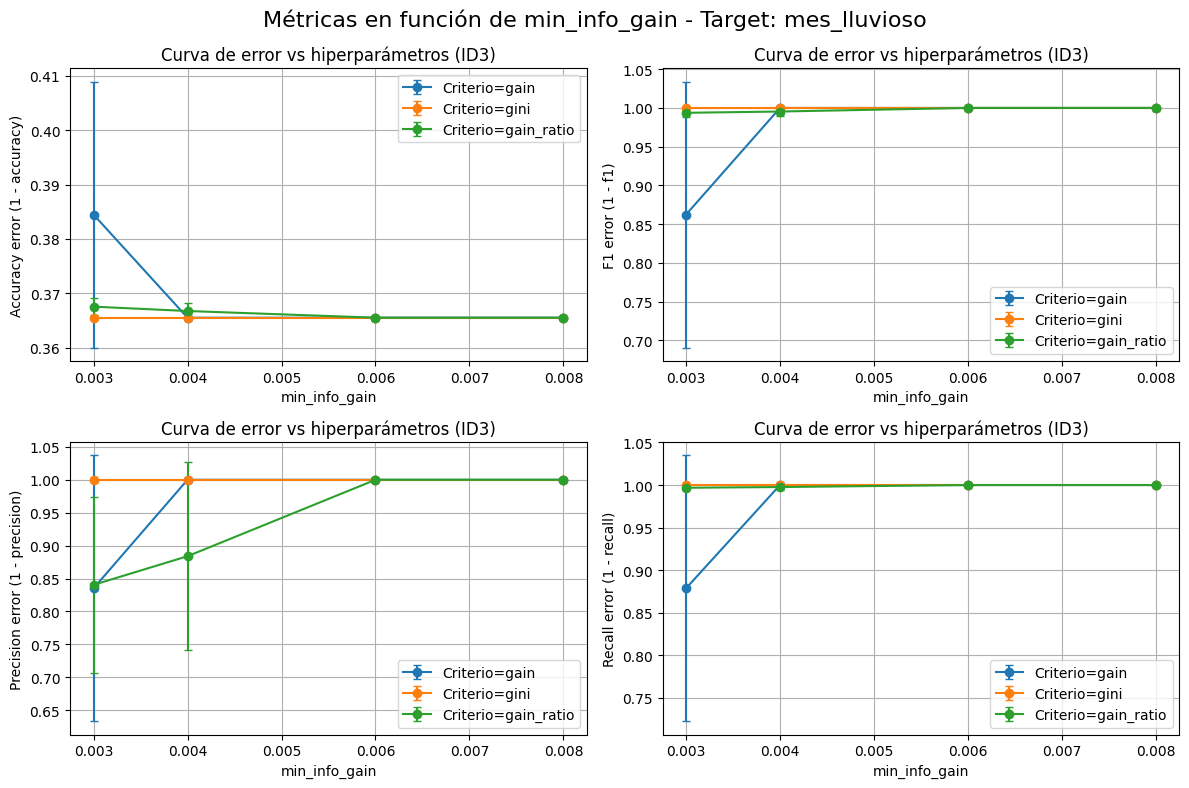

In [16]:
import matplotlib.pyplot as plt

for targete, df_val in resultados_validacion_id3.items():
    fig, axs = plt.subplots(2, 2, figsize=(12, 8))
    
    t.funcGraficaError(df_val, metric="accuracy", modelo="ID3", ax=axs[0,0])
    t.funcGraficaError(df_val, metric="f1", modelo="ID3", ax=axs[0,1])
    t.funcGraficaError(df_val, metric="precision", modelo="ID3", ax=axs[1,0])
    t.funcGraficaError(df_val, metric="recall", modelo="ID3", ax=axs[1,1])

    fig.suptitle(f"Métricas en función de min_info_gain - Target: {targete}", fontsize=16)
    plt.tight_layout()
    plt.show()

#tiempo est: 1seg


=== RESULTADOS FINALES PARA TARGET: dia_lluvioso ===

EVALUACIÓN FINAL EN TEST según mejor criterio por f-score:
mejor criterio:  gain mejor min_info_gain:  0.003
Accuracy : 0.6036945812807881
F1       : 0.28329621380846326
Recall   : 0.21428571428571427
Precision: 0.4178712220762155

EVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:
mejor criterio:  gain mejor min_info_gain:  0.004
Accuracy : 0.6344827586206897
F1       : 0.0
Recall   : 0.0
Precision: 0.0

MATRIZ DE CONFUSIÓN (TEST) según mejor criterio por f-score


C:\Users\cabre\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


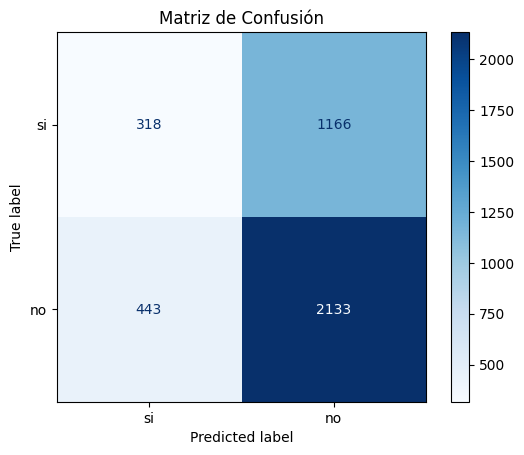


MATRIZ DE CONFUSIÓN (TEST) según mejor criterio por accuracy


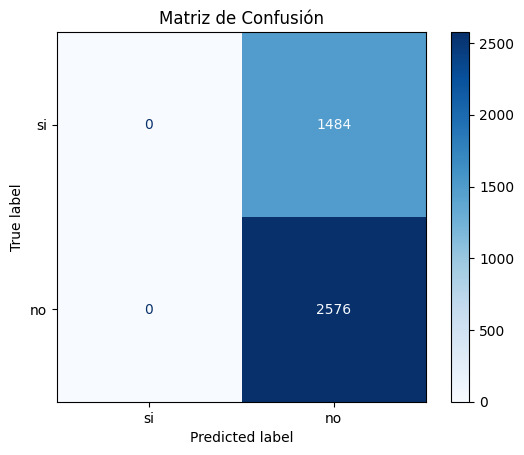


=== RESULTADOS FINALES PARA TARGET: mes_lluvioso ===

EVALUACIÓN FINAL EN TEST según mejor criterio por f-score:
mejor criterio:  gain mejor min_info_gain:  0.003
Accuracy : 0.6036945812807881
F1       : 0.28329621380846326
Recall   : 0.21428571428571427
Precision: 0.4178712220762155

EVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:
mejor criterio:  gain mejor min_info_gain:  0.004
Accuracy : 0.6344827586206897
F1       : 0.0
Recall   : 0.0
Precision: 0.0

MATRIZ DE CONFUSIÓN (TEST) según mejor criterio por f-score


C:\Users\cabre\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


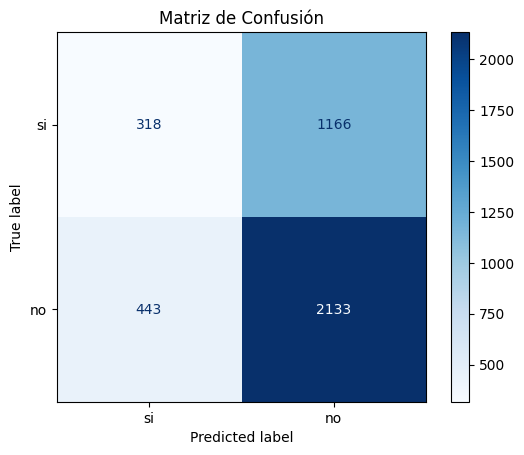


MATRIZ DE CONFUSIÓN (TEST) según mejor criterio por accuracy


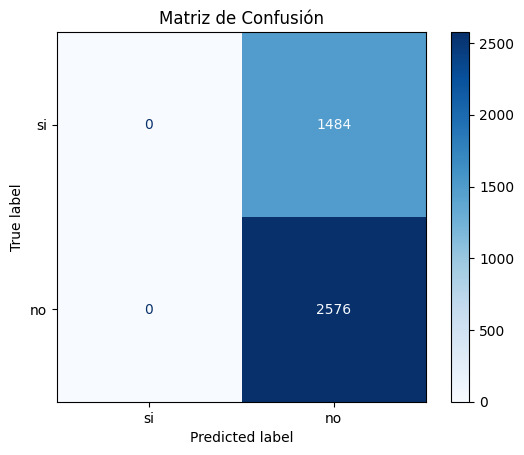

In [17]:
# Evaluación final en test según mejores configuraciones ID3 modificado
for target, res in resultados_validacion_id3.items():
    print(f"\n=== RESULTADOS FINALES PARA TARGET: {target} ===")
    y_pred_f = t.testearModelo("ID3", best_cfg_F, X_train, y_train, X_test)
    print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por f-score:")
    t.imprimirMetricas("ID3", best_cfg_F, y_test, y_pred_f)

    y_pred_a = t.testearModelo("ID3", best_cfg_A, X_train, y_train, X_test)
    print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:")
    t.imprimirMetricas("ID3", best_cfg_A, y_test, y_pred_a)

    # Matrices de confusión
    print("\nMATRIZ DE CONFUSIÓN (TEST) según mejor criterio por f-score")
    t.graficar_matriz_confusion(y_test, y_pred_f, labels=['si', 'no'])

    print("\nMATRIZ DE CONFUSIÓN (TEST) según mejor criterio por accuracy")
    t.graficar_matriz_confusion(y_test, y_pred_a, labels=['si', 'no'])

#timepo est: 1min

In [ ]:
#PRINT ARBOL ID3, descomentar si se prefiere, resulta un arbol muy amplio

# arbol = t.generacion_ID3(S, list(X.columns), "dia_lluvioso", best_cfg_F["min_info_gain"], best_cfg_F["criterio"])
# dot = t.graficar_arbol(arbol)
# dot.render("ARBOL mejor parametrización según f-score", format="png", view=True)

In [27]:
# -------------------------------------------- RANDOM FOREST -------------------------------------------------
import algoritmos_clasificacion as t
import importlib
importlib.reload(t)

# Cargar dataset
S2 = t.cargarDataset("data_dia_c")

# Definir los atributos y objetivo validos
# Configuración atributos y objetivo válidos
if "fase_lunar" in X_config:
    X_config.remove("fase_lunar") #eliminamos la fase lunar

#configuración de hiperparámetros a evaluar
n_estimators_values = [100, 200, 300, 500]

resultados_validacion_rf = {}

for target in y_config:
    X = S2[X_config]

    y = S2[target].squeeze() #pasa de df a serie

    # Train/Test split (80/20 estratificado)
    X_train, X_test, y_train, y_test, = t.split_data(X,y)

    # Validación cruzada para selección de hiperparámetros
    df_validacion_rf, best_cfg_F, best_cfg_A, best_cfg_P, best_cfg_R = t.validarModelo(X_train, y_train, n_splits=5, hiperparams=n_estimators_values)

    print(f"\n Resultados CV - {target}")
    print(df_validacion_rf.round(4).to_string(index=False))

    resultados_validacion_rf[target] = {
        "df": df_validacion_rf,
        "best_F": best_cfg_F,
        "best_A": best_cfg_A,
        "best_P": best_cfg_P,
        "best_R": best_cfg_R,
        "X_train": X_train,
        "y_train": y_train,
        "X_test": X_test,
        "y_test": y_test
    }

#tiempo est: 2 min



 Resultados CV - dia_lluvioso
 n_estimators  accuracy_mean  accuracy_std  f1_mean  f1_std  recall_mean  recall_std  precision_mean  precision_std
          100         0.7781        0.0047   0.1478  0.0223       0.0870      0.0141          0.4969         0.0576
          200         0.7788        0.0045   0.1439  0.0133       0.0839      0.0083          0.5104         0.0592
          300         0.7799        0.0037   0.1423  0.0128       0.0825      0.0087          0.5290         0.0567
          500         0.7797        0.0039   0.1395  0.0075       0.0806      0.0050          0.5259         0.0608

 Resultados CV - mes_lluvioso
 n_estimators  accuracy_mean  accuracy_std  f1_mean  f1_std  recall_mean  recall_std  precision_mean  precision_std
          100         0.6440        0.0053   0.2604  0.0109       0.1715      0.0075          0.5412         0.0236
          200         0.6462        0.0047   0.2540  0.0110       0.1648      0.0074          0.5540         0.0220
          

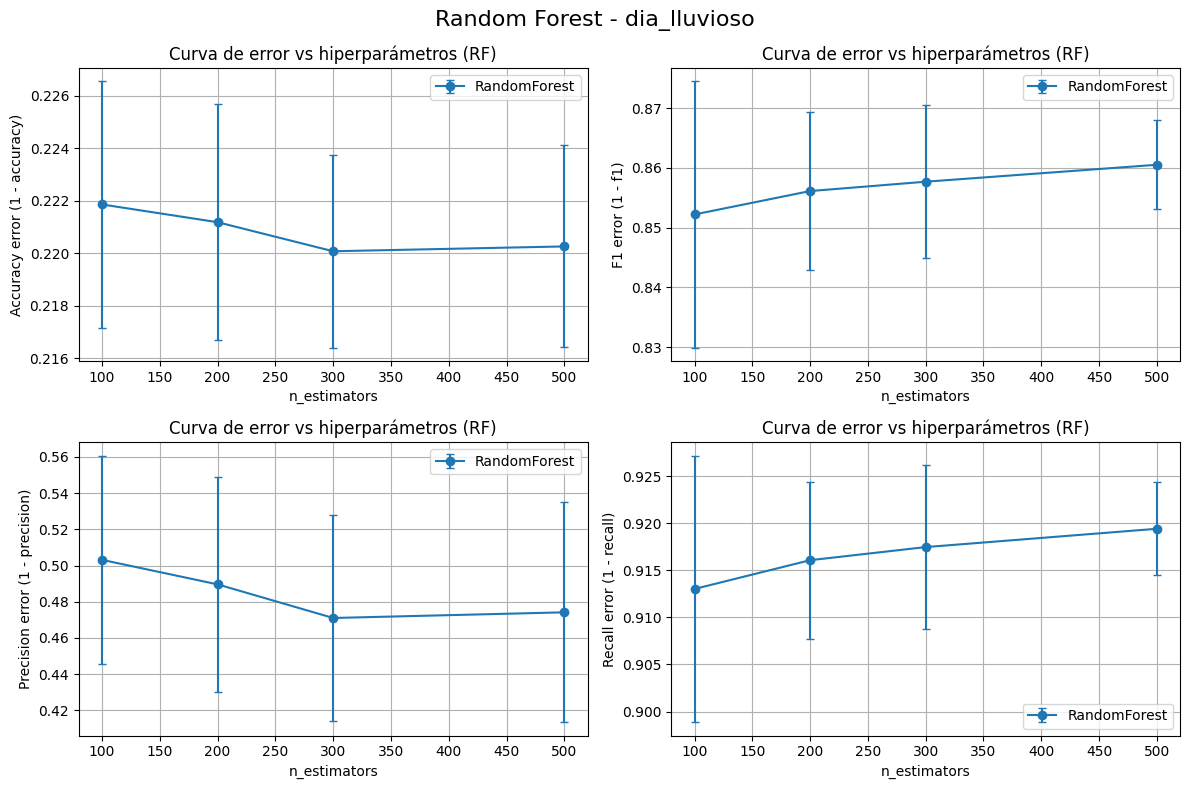

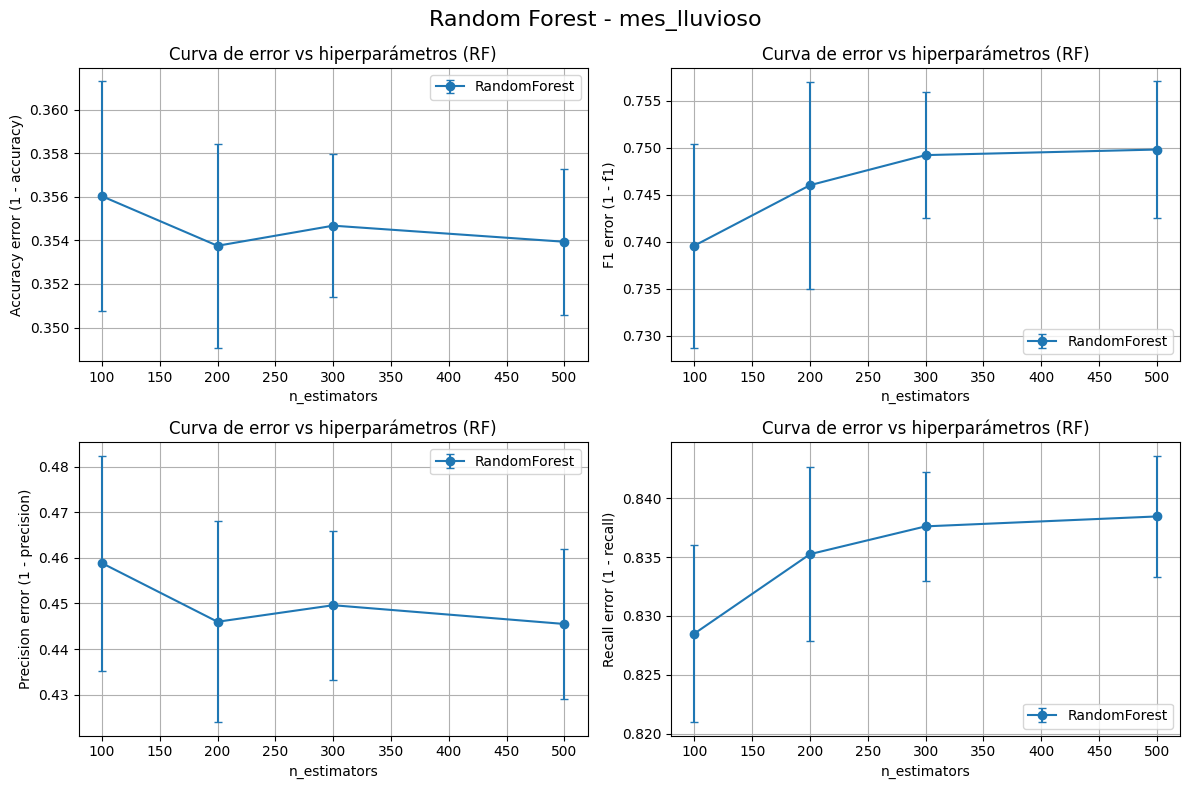

In [29]:
import matplotlib.pyplot as plt

for targete, res in resultados_validacion_rf.items():
    fig, axs = plt.subplots(2, 2, figsize=(12, 8))

    df_validacion_rf = res["df"]

    fig.suptitle(f"Random Forest - {targete}", fontsize=16)

    t.funcGraficaError(df_validacion_rf, metric="accuracy", modelo="RF", ax=axs[0,0])
    t.funcGraficaError(df_validacion_rf, metric="f1", modelo="RF", ax=axs[0,1])
    t.funcGraficaError(df_validacion_rf, metric="precision", modelo="RF", ax=axs[1,0])
    t.funcGraficaError(df_validacion_rf, metric="recall", modelo="RF", ax=axs[1,1])

    plt.tight_layout()
    plt.show()
    

#tiempo est: 1seg


=== RESULTADOS FINALES PARA: dia_lluvioso ===

EVALUACIÓN FINAL EN TEST según mejor criterio por f-score:
nro arboles:  100
Accuracy : 0.7726600985221674
F1       : 0.16621499548328816
Recall   : 0.4444444444444444
Precision: 0.10222222222222223

EVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:
nro arboles:  300
Accuracy : 0.7721674876847291
F1       : 0.16289592760180996
Recall   : 0.1
Precision: 0.43902439024390244

MATRIZ DE CONFUSIÓN (TEST) según mejor criterio por f-score


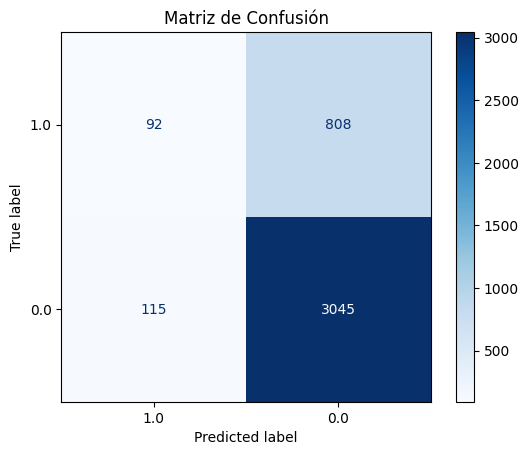


MATRIZ DE CONFUSIÓN (TEST) según mejor criterio por accuracy


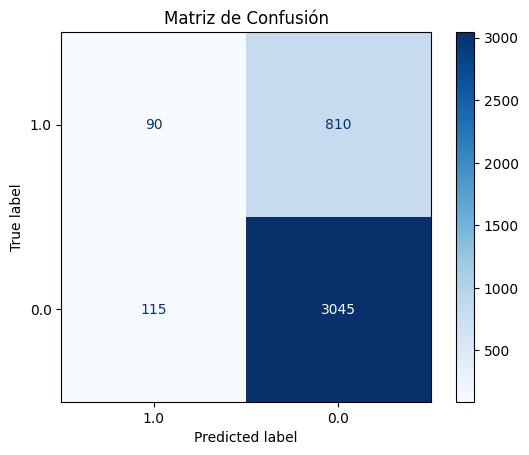


=== RESULTADOS FINALES PARA: mes_lluvioso ===

EVALUACIÓN FINAL EN TEST según mejor criterio por f-score:
nro arboles:  100
Accuracy : 0.6431034482758621
F1       : 0.2663291139240506
Recall   : 0.5356415478615071
Precision: 0.17722371967654987

EVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:
nro arboles:  200
Accuracy : 0.6480295566502463
F1       : 0.25766233766233765
Recall   : 0.16711590296495957
Precision: 0.562358276643991

MATRIZ DE CONFUSIÓN (TEST) según mejor criterio por f-score


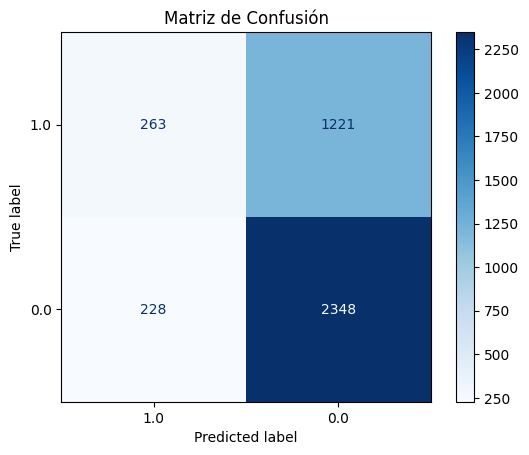


MATRIZ DE CONFUSIÓN (TEST) según mejor criterio por accuracy


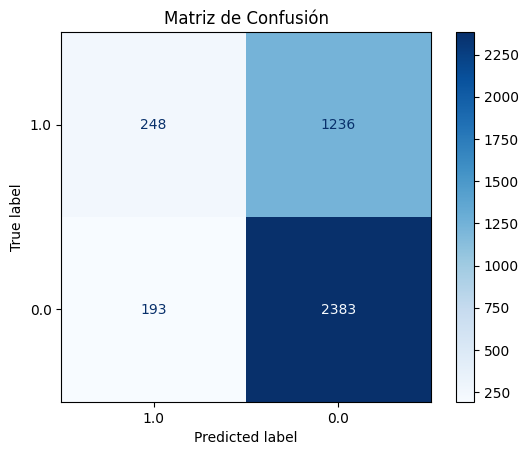

In [31]:
# Evaluación final en test según mejores configuraciones RANDOM FOREST sickit learn

for targ in y_config:
    X_train = resultados_validacion_rf[targ]["X_train"]
    y_train = resultados_validacion_rf[targ]["y_train"]
    X_test = resultados_validacion_rf[targ]["X_test"]
    y_test = resultados_validacion_rf[targ]["y_test"]
    best_cfg_F = resultados_validacion_rf[targ]["best_F"]
    best_cfg_A = resultados_validacion_rf[targ]["best_A"]

    print(f"\n=== RESULTADOS FINALES PARA: {targ} ===")

    y_pred_f = t.testearModelo("RF", best_cfg_F, X_train, y_train, X_test)
    print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por f-score:")
    t.imprimirMetricas("RF", best_cfg_F, y_pred_f, y_test)

    y_pred_a = t.testearModelo("RF", best_cfg_A, X_train, y_train, X_test)
    print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:")
    t.imprimirMetricas("RF", best_cfg_A, y_test, y_pred_a)

    # Matrices de confusión
    print("\nMATRIZ DE CONFUSIÓN (TEST) según mejor criterio por f-score")
    t.graficar_matriz_confusion(y_test, y_pred_f, labels=[1.0, 0.0])

    print("\nMATRIZ DE CONFUSIÓN (TEST) según mejor criterio por accuracy")
    t.graficar_matriz_confusion(y_test, y_pred_a, labels=[1.0, 0.0])

#tiempo est: 10seg